In [9]:

import heapq
import time
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("All libraries imported successfully!")


All libraries imported successfully!


In [10]:

# Start and goal positions
START = (0, 0)
GOAL = (14, 14)


def heuristic(a, b):
    """Manhattan distance for A*."""
    return abs(a[0] - b[0]) + abs(a[1] - b[1])


def get_neighbors(grid, position):
    """Return valid up, down, left and right neighbors."""
    rows, cols = grid.shape
    r, c = position

    moves = [(1, 0), (-1, 0), (0, 1), (0, -1)]
    neighbors = []

    for dr, dc in moves:
        nr, nc = r + dr, c + dc

        if (0 <= nr < rows and
                0 <= nc < cols and
                grid[nr, nc] == 0):
            neighbors.append((nr, nc))

    return neighbors


def reconstruct_path(parent, current):
    """Rebuild path from goal back to start."""
    path = []

    while current is not None:
        path.append(current)
        current = parent[current]

    return path[::-1]


def search(grid, start, goal, algorithm="A*"):
    """Run A* or Dijkstra and return path and metrics."""
    start_time = time.perf_counter()

    # Handle blocked start or goal
    if grid[start] == 1 or grid[goal] == 1:
        return None, 0, time.perf_counter() - start_time

    # Priority queue entries: (priority, cost, position)
    frontier = []
    initial_h = heuristic(start, goal) if algorithm == "A*" else 0

    heapq.heappush(frontier, (initial_h, 0, start))

    cost = {start: 0}
    parent = {start: None}
    explored = set()

    while frontier:
        priority, current_cost, current = heapq.heappop(frontier)

        # Ignore outdated queue entries
        if current_cost != cost.get(current):
            continue

        if current in explored:
            continue

        explored.add(current)

        if current == goal:
            path = reconstruct_path(parent, goal)
            elapsed = time.perf_counter() - start_time
            return path, len(explored), elapsed

        for neighbor in get_neighbors(grid, current):
            new_cost = current_cost + 1

            if new_cost < cost.get(neighbor, float("inf")):
                cost[neighbor] = new_cost
                parent[neighbor] = current

                if algorithm == "A*":
                    h = heuristic(neighbor, goal)
                else:
                    h = 0

                heapq.heappush(
                    frontier,
                    (new_cost + h, new_cost, neighbor)
                )

    elapsed = time.perf_counter() - start_time
    return None, len(explored), elapsed


print("A* and Dijkstra functions are ready!")


A* and Dijkstra functions are ready!


In [11]:

def make_grid(density, seed, size=15):
    """Generate a random grid with a reachable goal."""
    rng = np.random.default_rng(seed)

    for attempt in range(300):
        grid = (rng.random((size, size)) < density).astype(int)

        # Keep start and goal open
        grid[START] = 0
        grid[GOAL] = 0

        # Accept only grids with a valid path
        path, _, _ = search(grid, START, GOAL, "A*")

        if path is not None:
            return grid

    # Safe fallback if no reachable random grid is found
    print("Using an open grid as a fallback for density:", density)
    return np.zeros((size, size), dtype=int)


densities = {
    "Low (10%)": 0.10,
    "Medium (25%)": 0.25,
    "High (35%)": 0.35
}

results = []
test_grids = {}
saved_paths = {}

for index, (level, density) in enumerate(densities.items()):
    grid = make_grid(density, seed=100 + index)
    test_grids[level] = grid

    for algorithm in ["A*", "Dijkstra"]:
        path, explored, runtime = search(
            grid, START, GOAL, algorithm
        )

        saved_paths[(level, algorithm)] = path

        results.append({
            "Obstacle_Level": level,
            "Algorithm": algorithm,
            "Path_Found": path is not None,
            "Path_Length": len(path) - 1 if path else -1,
            "Nodes_Explored": explored,
            "Runtime_Seconds": round(runtime, 6)
        })

# Display performance results
results_df = pd.DataFrame(results)
display(results_df)

print("All maze tests completed!")


,Obstacle_Level,Algorithm,Path_Found,Path_Length,Nodes_Explored,Runtime_Seconds
0,Low (10%),A*,True,28,195,0.000804
1,Low (10%),Dijkstra,True,28,206,0.000971
2,Medium (25%),A*,True,28,117,0.000517
3,Medium (25%),Dijkstra,True,28,172,0.001104
4,High (35%),A*,True,28,99,0.000528
5,High (35%),Dijkstra,True,28,131,0.000436


All maze tests completed!


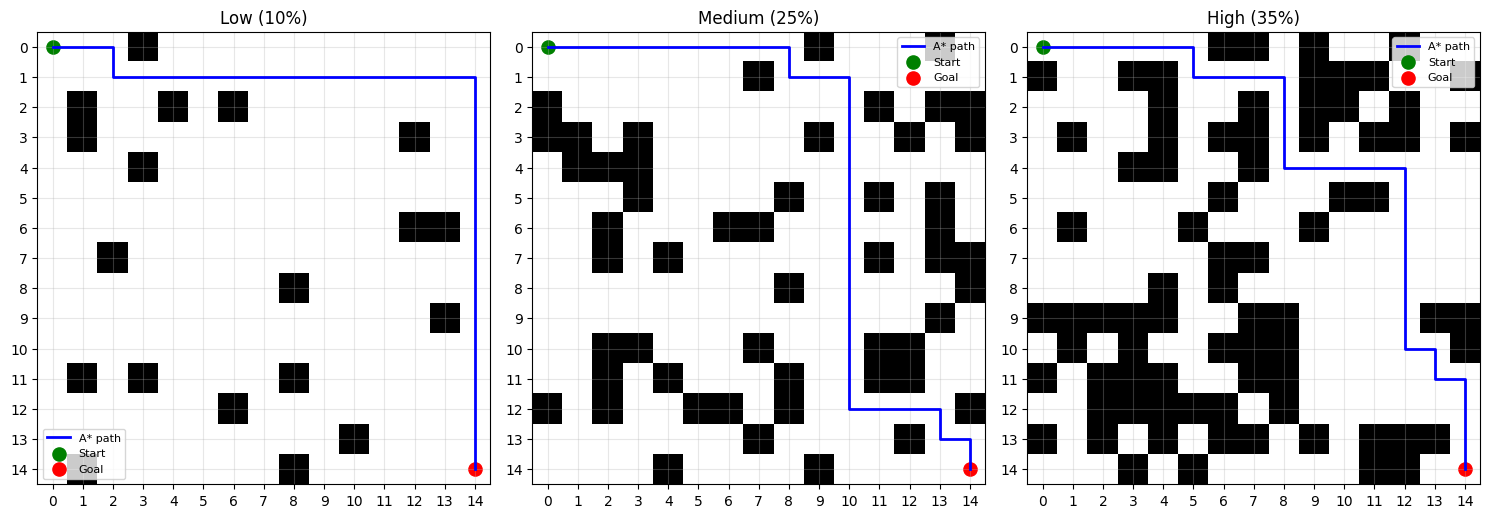

In [12]:

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (level, grid) in zip(axes, test_grids.items()):
    ax.imshow(grid, cmap="Greys", vmin=0, vmax=1)

    path = saved_paths[(level, "A*")]

    if path is not None:
        rows = [p[0] for p in path]
        cols = [p[1] for p in path]
        ax.plot(cols, rows, color="blue", linewidth=2, label="A* path")

    ax.scatter(
        START[1], START[0],
        color="green", s=90, label="Start"
    )
    ax.scatter(
        GOAL[1], GOAL[0],
        color="red", s=90, label="Goal"
    )

    ax.set_title(level)
    ax.set_xticks(range(grid.shape[1]))
    ax.set_yticks(range(grid.shape[0]))
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()


In [13]:

csv_filename = "pathfinding_performance_logs.csv"

results_df.to_csv(csv_filename, index=False)

print("CSV file saved:", csv_filename)

# Download the results to your computer
from google.colab import files
files.download(csv_filename)


CSV file saved: pathfinding_performance_logs.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:

# Q-Learning: train an agent to navigate the maze

import random
import numpy as np
import matplotlib.pyplot as plt
import time

def train_q_learning(
    grid, start, goal,
    episodes=3000,
    alpha=0.1,
    gamma=0.95,
    epsilon=1.0
):
    rows, cols = grid.shape

    # Actions: down, up, right, left
    moves = [(1, 0), (-1, 0), (0, 1), (0, -1)]
    q_table = np.zeros((rows * cols, 4))

    def state_id(position):
        return position[0] * cols + position[1]

    def valid_actions(position):
        r, c = position
        actions = []

        for action, (dr, dc) in enumerate(moves):
            nr, nc = r + dr, c + dc

            if (0 <= nr < rows and 0 <= nc < cols
                    and grid[nr, nc] == 0):
                actions.append(action)

        return actions

    episode_rewards = []
    start_time = time.perf_counter()

    for episode in range(episodes):
        position = start
        total_reward = 0
        current_epsilon = max(0.05, epsilon * (1 - episode / episodes))

        for _ in range(rows * cols * 4):
            actions = valid_actions(position)

            if not actions:
                break

            # Explore or choose the best learned action
            if random.random() < current_epsilon:
                action = random.choice(actions)
            else:
                action = max(
                    actions,
                    key=lambda a: q_table[state_id(position), a]
                )

            dr, dc = moves[action]
            next_position = (position[0] + dr, position[1] + dc)

            # Reward reaching the goal; small penalty per step
            reward = 100 if next_position == goal else -1

            next_actions = valid_actions(next_position)

            if next_position == goal or not next_actions:
                future_value = 0
            else:
                future_value = max(
                    q_table[state_id(next_position), a]
                    for a in next_actions
                )

            s = state_id(position)

            q_table[s, action] += alpha * (
                reward + gamma * future_value
                - q_table[s, action]
            )

            total_reward += reward
            position = next_position

            if position == goal:
                break

        episode_rewards.append(total_reward)

    training_time = time.perf_counter() - start_time

    # Follow learned values to extract a path
    path = [start]
    position = start
    visited = {start}

    for _ in range(rows * cols):
        if position == goal:
            break

        actions = valid_actions(position)

        # Avoid getting stuck in a loop
        actions = [
            a for a in actions
            if (position[0] + moves[a][0],
                position[1] + moves[a][1]) not in visited
        ]

        if not actions:
            break

        action = max(
            actions,
            key=lambda a: q_table[state_id(position), a]
        )

        dr, dc = moves[action]
        position = (position[0] + dr, position[1] + dc)

        path.append(position)
        visited.add(position)

    if path[-1] != goal:
        path = None

    return q_table, path, episode_rewards, training_time


# Train on the medium-obstacle maze from Step 4
q_grid = test_grids["Medium (25%)"]

q_table, q_path, rewards, q_runtime = train_q_learning(
    q_grid, START, GOAL
)

print("Q-Learning training completed!")
print("Episodes:", len(rewards))
print("Path found:", q_path is not None)
print("Path length:", len(q_path) - 1 if q_path else "No path")
print("Training time (seconds):", round(q_runtime, 4))


Q-Learning training completed!
Episodes: 3000
Path found: True
Path length: 28
Training time (seconds): 2.8991


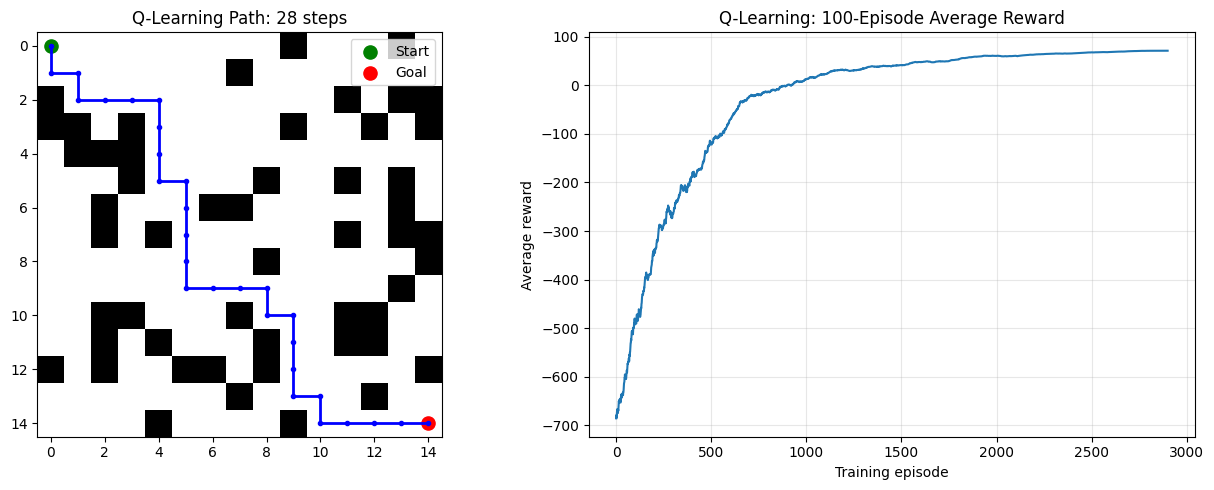

In [15]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: learned path
axes[0].imshow(q_grid, cmap="Greys", vmin=0, vmax=1)

if q_path is not None:
    path_rows = [p[0] for p in q_path]
    path_cols = [p[1] for p in q_path]

    axes[0].plot(
        path_cols, path_rows,
        color="blue", linewidth=2, marker="o", markersize=3
    )
    axes[0].set_title(
        f"Q-Learning Path: {len(q_path) - 1} steps"
    )
else:
    axes[0].set_title("No learned path yet; train for more episodes")

axes[0].scatter(START[1], START[0], color="green", s=90, label="Start")
axes[0].scatter(GOAL[1], GOAL[0], color="red", s=90, label="Goal")
axes[0].legend()

# Right: reward trend during training
window = 100
if len(rewards) >= window:
    moving_avg = np.convolve(
        rewards, np.ones(window) / window, mode="valid"
    )
    axes[1].plot(moving_avg)
    axes[1].set_title("Q-Learning: 100-Episode Average Reward")
else:
    axes[1].plot(rewards)
    axes[1].set_title("Reward per Episode")

axes[1].set_xlabel("Training episode")
axes[1].set_ylabel("Average reward")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [16]:

q_result = {
    "Obstacle_Level": "Medium (25%)",
    "Algorithm": "Q-Learning",
    "Path_Found": q_path is not None,
    "Path_Length": len(q_path) - 1 if q_path else -1,
    "Nodes_Explored": np.nan,
    "Runtime_Seconds": round(q_runtime, 6)
}

# Add Q-Learning result to the existing table
final_results = pd.concat(
    [results_df, pd.DataFrame([q_result])],
    ignore_index=True
)

display(final_results)

final_results.to_csv(
    "final_pathfinding_results.csv", index=False
)

from google.colab import files
files.download("final_pathfinding_results.csv")


,Obstacle_Level,Algorithm,Path_Found,Path_Length,Nodes_Explored,Runtime_Seconds
0,Low (10%),A*,True,28,195.0,0.000804
1,Low (10%),Dijkstra,True,28,206.0,0.000971
2,Medium (25%),A*,True,28,117.0,0.000517
3,Medium (25%),Dijkstra,True,28,172.0,0.001104
4,High (35%),A*,True,28,99.0,0.000528
5,High (35%),Dijkstra,True,28,131.0,0.000436
6,Medium (25%),Q-Learning,True,28,NaN,2.899099


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>